# Beach season case study

Pick a year, find the heavy rain days in it, and see what happened to Toronto's beaches in the days that followed — the same check done for 2021 in `precipitation_model.ipynb`, but swappable to any season with data (2007-2026).

**To look at a different season:** change `YEAR` in Part 1 and re-run the whole notebook.

## Part 1. Choose the season

In [1]:
YEAR = 2021
HEAVY_RAIN_MM = 25.0   # a day with at least this much rain counts as "heavy rain"
DAYS_AFTER = 4         # how many days after each heavy rain day to show
PRIOR_RAIN_OVERLAP_MM = 10.0  # flag an event if at least this much rain also fell in the 3 days before it

## Part 2. Load that year's rainfall

Environment and Climate Change Canada's daily files are one per year, named `en_climate_daily_ON_6158355_<year>_P1D.csv`. If `YEAR` doesn't have a downloaded file yet, this cell fails with a clear message rather than a confusing pandas error.

In [2]:
from pathlib import Path
import pandas as pd

weather_path = Path(f"../data/Toronto Daily Weather/en_climate_daily_ON_6158355_{YEAR}_P1D.csv")
if not weather_path.exists():
    raise FileNotFoundError(
        f"No weather file for {YEAR} at {weather_path}. "
        "Download it from https://climate.weather.gc.ca/climate_data/daily_data_e.html?StationID=31688 "
        "and drop it into data/Toronto Daily Weather/ before re-running."
    )

weather = pd.read_csv(weather_path, encoding="utf-8-sig", usecols=["Date/Time", "Total Precip (mm)"])
weather.columns = ["date", "precip_mm"]
weather["date"] = pd.to_datetime(weather["date"])
weather = weather.sort_values("date").reset_index(drop=True)

print(f"{YEAR}: {weather['precip_mm'].notna().sum()} / {len(weather)} days with a precipitation reading")

2021: 362 / 365 days with a precipitation reading


## Part 3. Load that year's beach readings

Same cleaning as `beach_quality.ipynb`: drop samples with no E. coli result, then average each beach's sampling sites into one daily number. `unsafe` marks a beach-day that exceeded Toronto's 100 E.coli/100mL standard.

In [3]:
df = pd.read_csv("../data/Toronto EColi Data/torontowater.csv")
df["collectionDate"] = pd.to_datetime(df["collectionDate"])
readings = df.dropna(subset=["eColi"]).copy()

daily = readings.groupby(["beachId", "beachName", "collectionDate"], as_index=False).agg(
    avg_eColi=("eColi", "mean"),
)
daily["unsafe"] = daily["avg_eColi"] > 100

season = daily[daily["collectionDate"].dt.year == YEAR]

if season.empty:
    raise ValueError(f"No beach samples recorded for {YEAR}. Try a different year.")

season_start, season_end = season["collectionDate"].min(), season["collectionDate"].max()
print(f"{YEAR} sampling season: {season_start.date()} to {season_end.date()}")
print(f"season baseline % unsafe: {season['unsafe'].mean() * 100:.1f}%")

2021 sampling season: 2021-05-25 to 2021-09-06
season baseline % unsafe: 22.0%


## Part 4. Find the heavy rain days

Searches the **whole calendar year**, not just the sampling season — a heavy rain day right before or after the season tells you something too (there's just no beach data to check it against).

In [4]:
heavy = weather[weather["precip_mm"] >= HEAVY_RAIN_MM].sort_values("date")

print(f"Heavy rain days (>= {HEAVY_RAIN_MM}mm) in {YEAR}:")
heavy[["date", "precip_mm"]]

Heavy rain days (>= 25.0mm) in 2021:


,date,precip_mm
84,2021-03-26,28.4
179,2021-06-29,25.0
188,2021-07-08,26.8
264,2021-09-22,49.9


## Part 5. What happened in the days after each one

For every heavy rain day inside the sampling season, the city-wide % of beaches flagged unsafe for each of the next few days, compared against the season baseline above. An event gets an automatic caveat if more rain also fell in the 3 days before it — that earlier rain could be driving the same spike, muddying a clean read on this event alone.

In [5]:
by_day = season.groupby("collectionDate").agg(n_beaches=("unsafe", "size"), pct_unsafe=("unsafe", "mean"))
by_day["pct_unsafe"] = (by_day["pct_unsafe"] * 100).round(0)

event_tables = {}
for _, row in heavy.iterrows():
    hd = row["date"]
    print(f"\n--- {hd.date()} ({row['precip_mm']}mm) ---")
    if not (season_start <= hd <= season_end):
        print("  (outside the sampling season -- no beach data to check)")
        continue
    prior_3d = weather[(weather["date"] >= hd - pd.Timedelta(days=3)) & (weather["date"] < hd)]["precip_mm"].sum()
    if prior_3d >= PRIOR_RAIN_OVERLAP_MM:
        print(f"  note: {prior_3d:.1f}mm also fell in the 3 days before this one -- the signal below may be mixing two events")
    window = by_day.loc[hd : hd + pd.Timedelta(days=DAYS_AFTER)]
    event_tables[hd] = window
    print(window)


--- 2021-03-26 (28.4mm) ---
  (outside the sampling season -- no beach data to check)

--- 2021-06-29 (25.0mm) ---
                n_beaches  pct_unsafe
collectionDate                       
2021-06-29              9        11.0
2021-06-30             10        60.0
2021-07-01             10        70.0
2021-07-02             10        20.0
2021-07-03             10        60.0

--- 2021-07-08 (26.8mm) ---
                n_beaches  pct_unsafe
collectionDate                       
2021-07-08              7        43.0
2021-07-09             10        70.0
2021-07-10             10        40.0
2021-07-11             10        10.0
2021-07-12              9        11.0

--- 2021-09-22 (49.9mm) ---
  (outside the sampling season -- no beach data to check)


## Part 6. Compare events side by side

Each heavy rain day inside the season as its own line: days since the rain on the x-axis, % of beaches unsafe on the y-axis. The dashed line is the season baseline.

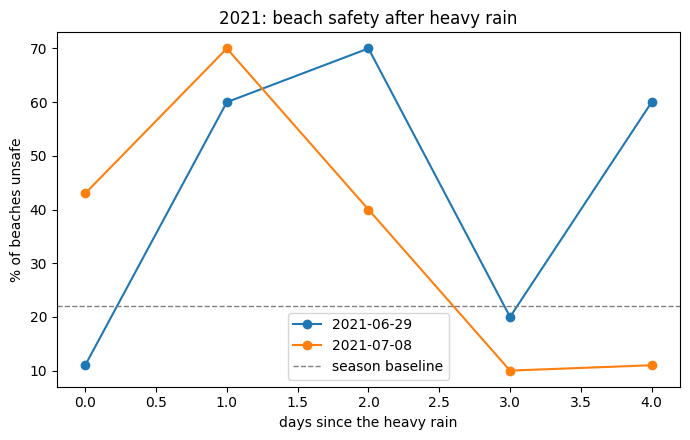

In [6]:
import matplotlib.pyplot as plt

if not event_tables:
    print("No in-season heavy rain events to plot for this year.")
else:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for hd, window in event_tables.items():
        days_since = (window.index - hd).days
        ax.plot(days_since, window["pct_unsafe"], marker="o", label=f"{hd.date()}")
    ax.axhline(season["unsafe"].mean() * 100, color="gray", linestyle="--", linewidth=1, label="season baseline")
    ax.set_xlabel("days since the heavy rain")
    ax.set_ylabel("% of beaches unsafe")
    ax.set_title(f"{YEAR}: beach safety after heavy rain")
    ax.legend()
    plt.tight_layout()
    plt.show()